In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns
from PIL import Image

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision import datasets
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

load_dotenv()

# 오류 발생시
sklearn.set_config(display="text")

# Shoe vs Sandal vs Boot Image Dataset
- [데이터셋 링크] https://www.kaggle.com/datasets/hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images

## 데이터 준비

In [2]:
base_path = r"C:\kdt_0900_hhj\ml\resource\dataset"
folder_name = r"SSBDataset"
file_path = os.path.join(base_path, folder_name)
file_path

'C:\\kdt_0900_hhj\\ml\\resource\\dataset\\SSBDataset'

In [3]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

os.makedirs(base_path, exist_ok=True)
api.dataset_download_files(r"hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images", path=base_path, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images
다운로드 완료


## 데이터 나누기

In [4]:
base_dataset = ImageFolder(root=file_path, transform=None)

In [5]:
total_size = len(base_dataset)
train_size = int(total_size * 0.8)
test_size = total_size - train_size

In [6]:
print(train_size, test_size)

12000 3000


In [7]:
train_subset, test_subset = random_split(base_dataset, [train_size, test_size], generator=torch.Generator().manual_seed(42))

In [8]:
print(len(train_subset), len(test_subset))

12000 3000


In [9]:
# MobileNetV2가 학습할 때 사용하는 이미지 정규화 기준값. 이미지 픽셀값을 정규화해서 MobileNet이 학습하기 좋은 형태로 맞춰준다
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

In [10]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)), 
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])
test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [11]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y

In [12]:
train_dataset = DatasetWrapper(train_subset, transform=train_transform)
test_dataset = DatasetWrapper(test_subset, transform=test_transform)

In [13]:
print(len(train_dataset), len(test_dataset))

12000 3000


In [14]:
class_dict = dict(enumerate(base_dataset.classes))
print(f"클래스 수: {class_dict}")
print(f"라벨 매핑: {base_dataset.class_to_idx}")
print(f"학습 데이터 샘플 수: {len(train_dataset)}")
print(f"검증 데이터 샘플 수: {len(test_dataset)}")

클래스 수: {0: 'Boot', 1: 'Sandal', 2: 'Shoe'}
라벨 매핑: {'Boot': 0, 'Sandal': 1, 'Shoe': 2}
학습 데이터 샘플 수: 12000
검증 데이터 샘플 수: 3000


In [15]:
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [16]:
imgs, labels = next(iter(train_dataloader))

In [17]:
print(imgs.size())

torch.Size([32, 3, 224, 224])


In [18]:
# 배치크기 32, RGB 색상 채널 3개, 이미지크기 가로세로 224x224

## 확인해보기

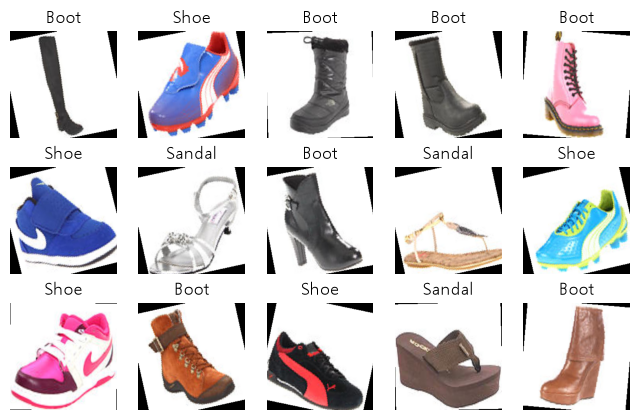

In [19]:
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(3, 5, figsize=(8, 5))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    img = img.cpu() * std + mean # 정규화 이전의 픽셀값으로 복원
    img = img.permute(1, 2, 0)
    ax.imshow(img)
    ax.set_title(class_dict[label.item()])
    ax.axis("off")

plt.show()

## 장치선택

In [20]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cuda


## 모델준비

In [21]:
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

### 모델 선정 이유


#### 데이터셋 특징
- 신발 이미지를 종류별로 분류하는 다중 클래스 이미지 분류 문제이다.
- 클래스는 3개, 이미지는 약 15,000장, 클래스마다 5,000장이 있다.
- 클래스별 데이터 수가 같아 데이터 불균형 문제는 적을 것으로 예상한다.
- 데이터셋 이미지의 촬영 각도와 배경이 일정하므로 배경이나 각도보다는 신발의 형태와 디자인 차이를 학습하는 것이 중요하다고 판단하였다.

#### 선정 이유
- MobileNetV2는 ResNet과 같은 모델에 비해 비교적 가볍고 계산량이 적어, 모델의 크기와 실행 효율을 고려하여 선택하였다.
- 또한 사전 학습된 가중치를 고정하고 마지막 분류층만 학습하면 학습해야 하는 파라미터 수를 줄일 수 있으므로 구글 코랩(Colab T4) 환경이나 개인 PC의 로컬 GPU/MPS 환경에서 학습할 때, 모델 용량이 가볍고 연산이 빨라 주어진 환경에서 효율적으로 학습할 수 있을 것으로 판단하였다.

다만, 데이터셋 이미지가 동일한 각도와 단조로운 배경 조건을 가지고 있어 학습 데이터에만 과적합(Overfitting)될 위험이 있으므로 데이터 전처리 단계에서 미세한 회전이나 크기 조절 등의 데이터 증강(Data Augmentation)을 적용해 대응하고자 한다.

In [22]:
model

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

## 모델프리징

In [23]:
for param in model.parameters():
    param.requires_grad = False

## 모델 수정

In [24]:
# 분류할 클래스가 3개라  out_features은 수정해야 한다

In [25]:
model.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=False),
    nn.Linear(model.classifier[1].in_features, 256),
    nn.BatchNorm1d(256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, 3)
)

In [26]:
print(model)

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

In [27]:
# 손실 함수
criterion = nn.CrossEntropyLoss()
# 최적화 도구
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

In [28]:
model = model.to(device)

## 학습

In [29]:
def train_one_epoch_shoes(model, dataloader, criterion, optimizer, device="cpu"):
    model.train() # 학습모드
    sum_losses = 0.0
    sum_accs = 0.0

    for i, (X_batch, y_batch) in enumerate(dataloader, 1):
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        batch_loss = 0.0
        
        # 학습
        optimizer.zero_grad() 
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()

        batch_loss += loss.item()
        sum_losses += batch_loss

        # 다중 클래스의 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

        if i % 20 == 0:
            print(f"[Batch {i}/{len(dataloader)}] Batch Loss: {batch_loss:.4f}, Batch Accuracy: {acc:.2f}%")

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)

    return avg_loss, avg_acc

In [30]:
@torch.no_grad() # 기울기를 계산x
def evaluate_shoes(model, dataloader, criterion, device="cpu"):
    model.eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_losses += loss.item()

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)
    
    return avg_loss, avg_acc

In [31]:
def train_model_shoes(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0

    # 학습
    print(f"========================= {model_name} 학습 시작 ============================")
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_shoes(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_shoes(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
        print(f"[Epoch: {epoch + 1}] | Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.2f}%")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    print(f"========================= {model_name} 학습 종료 ============================")
    return history

In [32]:
history = train_model_shoes(
    model=model,
    model_name="Mobilenet_shoes",
    train_loader=train_dataloader,
    val_loader=test_dataloader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=20,
    device=device,
    save_base_dir=os.path.join(base_path, "weights")
)

========================= Mobilenet_shoes 학습 시작 ============================
[Batch 20/375] Batch Loss: 0.5993, Batch Accuracy: 78.12%
[Batch 40/375] Batch Loss: 0.3749, Batch Accuracy: 90.62%
[Batch 60/375] Batch Loss: 0.3791, Batch Accuracy: 81.25%
[Batch 80/375] Batch Loss: 0.2184, Batch Accuracy: 90.62%
[Batch 100/375] Batch Loss: 0.4050, Batch Accuracy: 81.25%
[Batch 120/375] Batch Loss: 0.1762, Batch Accuracy: 93.75%
[Batch 140/375] Batch Loss: 0.1985, Batch Accuracy: 93.75%
[Batch 160/375] Batch Loss: 0.2959, Batch Accuracy: 84.38%
[Batch 180/375] Batch Loss: 0.2044, Batch Accuracy: 93.75%
[Batch 200/375] Batch Loss: 0.1504, Batch Accuracy: 93.75%
[Batch 220/375] Batch Loss: 0.2562, Batch Accuracy: 87.50%
[Batch 240/375] Batch Loss: 0.1467, Batch Accuracy: 93.75%
[Batch 260/375] Batch Loss: 0.2784, Batch Accuracy: 90.62%
[Batch 280/375] Batch Loss: 0.2314, Batch Accuracy: 87.50%
[Batch 300/375] Batch Loss: 0.2884, Batch Accuracy: 81.25%
[Batch 320/375] Batch Loss: 0.3425, Batch 

## 평가

In [33]:
best_model_path = os.path.join(base_path, r"weights", r"Mobilenet_shoes", r"best_model.pth")

model.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)

model = model.to(device)
model.eval()

print("최적 모델 로드 완료")

최적 모델 로드 완료


## Accuracy 측정

In [34]:
test_loss, test_acc = evaluate_shoes(
    model=model,
    dataloader=test_dataloader,
    criterion=criterion,
    device=device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

Test Loss: 0.1989
Test Accuracy: 93.10%


## 예측 시각화하기

In [35]:
imgs, labels = next(iter(test_dataloader))

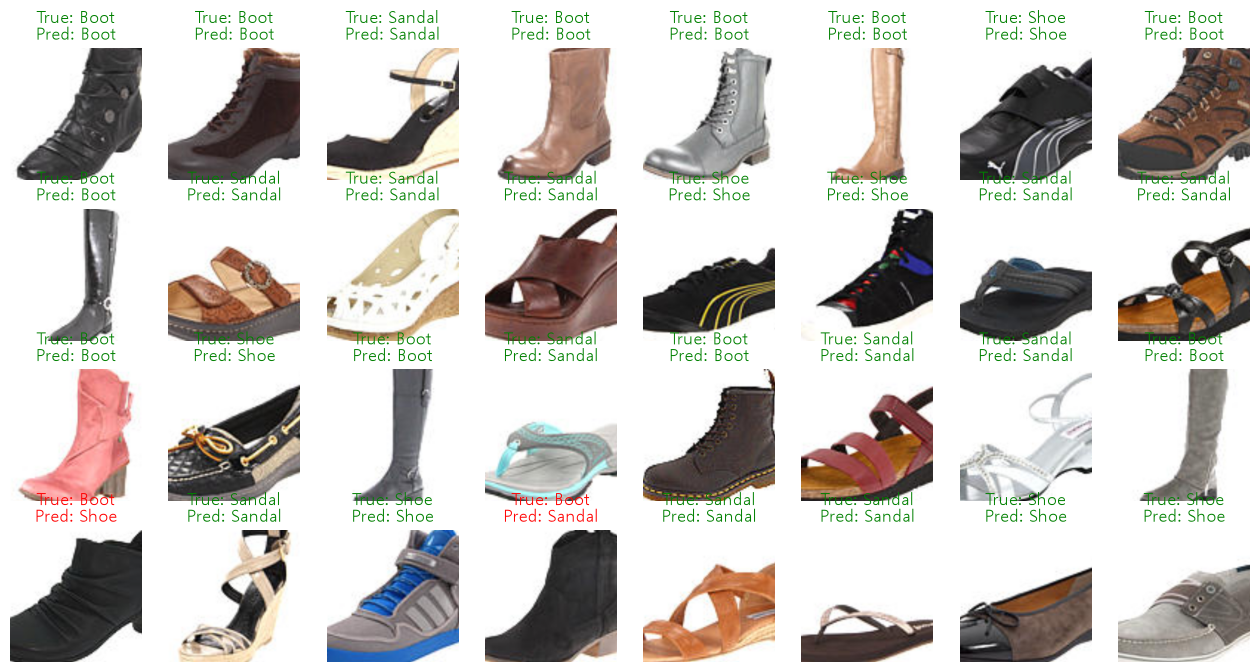

In [43]:
model.eval()
imgs_device = imgs.to(device)

with torch.no_grad():
    preds = model(imgs_device)
    pred_labels = preds.argmax(dim=1).cpu()

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

mean = np.array(mean).reshape(1, 1, 3)
std = np.array(std).reshape(1, 1, 3)

for ax, img, label, pred in zip(axes.flatten(), imgs, labels, pred_labels):
    img_np = img.permute(1, 2, 0).numpy()
    img_np = np.clip(img_np * std + mean, 0, 1)
    true_label = int(label.item())
    pred_label = int(pred.item())
    color = "green" if true_label == pred_label else "red"
    ax.imshow(img_np)
    ax.set_title(f"True: {class_dict[true_label]}\nPred: {class_dict[pred_label]}", color=color)
    ax.axis("off")

plt.show()

## f1-score 추가지표

In [37]:
from sklearn.metrics import f1_score, ConfusionMatrixDisplay

In [38]:
all_preds = []
all_labels = []

model.eval()

with torch.no_grad():
    for X_batch, y_batch in test_dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(X_batch)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.cpu().numpy())

f1 = f1_score(all_labels, all_preds, average="macro")

print(f"F1-score: {f1:.4f}")

F1-score: 0.9315


## confusion matrix

In [39]:
cm = confusion_matrix(all_labels, all_preds)
cm

array([[918,  22,  50],
       [  9, 887,  63],
       [  8,  55, 988]])

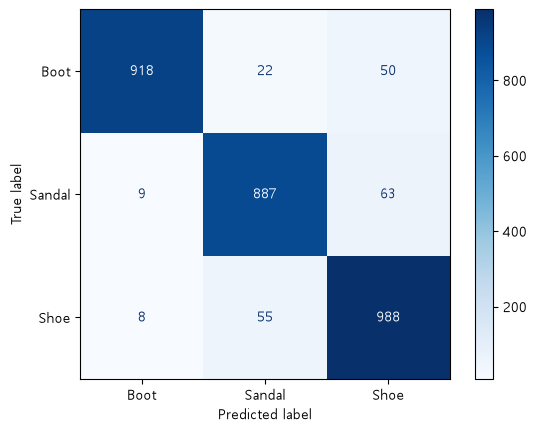

In [40]:
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Boot", "Sandal", "Shoe"])
cm_display.plot(cmap="Blues")
plt.show()

In [41]:
# 대각선 숫자: 정답을 맞힌 개수
# 대각선 밖 숫자: 다른 클래스로 틀리게 예측한 개수

# 대부분 잘 맞추는 것 같다. 그나마 샌달을 슈즈로 예측하는 오류가 가장 높게 나온것으로 보인다

## 오분류 찾기

In [47]:
model.eval()

incorrect_samples = []

with torch.no_grad():
    for imgs, labels in test_dataloader:
        imgs_device = imgs.to(device)

        preds = model(imgs_device)
        pred_labels = preds.argmax(dim=1).cpu()
        probs = torch.softmax(preds, dim=1).cpu()

        incorrect_mask = (pred_labels != labels)

        if incorrect_mask.any():
            for img, label, pred, prob in zip(imgs[incorrect_mask], labels[incorrect_mask], pred_labels[incorrect_mask], probs[incorrect_mask]):
                incorrect_samples.append({
                    "img": img,
                    "true_label": label.item(),
                    "pred_label": pred.item(),
                    "pred_prob": prob[pred.item()].item()
                })

print(incorrect_samples)

[{'img': tensor([[[ 2.2489,  2.2489,  2.2489,  ...,  1.7694,  1.1358,  0.4679],
         [ 2.2489,  2.2489,  2.2489,  ...,  0.7077,  0.1597, -0.3883],
         [ 2.2489,  2.2489,  2.2489,  ..., -0.3712, -0.8164, -1.2445],
         ...,
         [-0.9020, -1.0904, -1.1932,  ...,  2.2489,  2.2489,  2.2489],
         [ 0.5193,  0.3138,  0.0569,  ...,  2.2489,  2.2489,  2.2489],
         [ 1.9407,  1.7009,  1.3070,  ...,  2.2489,  2.2489,  2.2489]],

        [[ 2.4286,  2.4286,  2.4286,  ...,  1.9384,  1.2731,  0.5903],
         [ 2.4286,  2.4286,  2.4286,  ...,  0.8529,  0.2752, -0.3025],
         [ 2.4286,  2.4286,  2.4286,  ..., -0.2500, -0.7227, -1.1779],
         ...,
         [-0.7927, -0.9853, -1.0903,  ...,  2.4286,  2.4286,  2.4286],
         [ 0.6604,  0.4503,  0.1877,  ...,  2.4286,  2.4286,  2.4286],
         [ 2.1134,  1.8683,  1.4657,  ...,  2.4286,  2.4286,  2.4286]],

        [[ 2.6400,  2.6400,  2.6400,  ...,  2.1520,  1.4722,  0.7576],
         [ 2.6400,  2.6400,  2.6400,

In [48]:
print(incorrect_mask)

tensor([False, False, False,  True, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False,  True, False,
        False, False, False, False])


In [49]:
for sample in incorrect_samples[:10]:
    print(f"정답 : {base_dataset.classes[sample["true_label"]]} | 예측 : {base_dataset.classes[sample["pred_label"]]} | 예측 확률 : {round(sample["pred_prob"], 2)}")

정답 : Boot | 예측 : Shoe | 예측 확률 : 0.77
정답 : Boot | 예측 : Sandal | 예측 확률 : 0.81
정답 : Sandal | 예측 : Shoe | 예측 확률 : 0.92
정답 : Sandal | 예측 : Shoe | 예측 확률 : 0.85
정답 : Sandal | 예측 : Shoe | 예측 확률 : 0.66
정답 : Sandal | 예측 : Shoe | 예측 확률 : 0.63
정답 : Shoe | 예측 : Sandal | 예측 확률 : 0.67
정답 : Shoe | 예측 : Sandal | 예측 확률 : 0.6
정답 : Sandal | 예측 : Shoe | 예측 확률 : 0.54
정답 : Boot | 예측 : Shoe | 예측 확률 : 0.46


## 모델 개선 아이디어

### 1. 데이터 증강 강화
- 방법: 학습 데이터에 좌우 반전 및 작은 각도의 회전을 적용한다.
- 근거: 다양한 형태의 신발 이미지를 학습시켜 데이터에 대한 과도한 의존을 줄이고, 새로운 이미지에 대한 일반화 성능을 높일 수 있다.

### 2. 학습률 조정
- 방법: Adam 옵티마이저의 학습률을 0.001 에서 0.0001 로 변경해 성능을 비교한다.
- 근거: 학습률을 낮추면 가중치의 변화 폭이 작아져 보다 세밀한 학습이 가능하며, 검증 성능이 개선될 수 있다.

In [51]:
#1. 데이터 증강 강화

train_transform2 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05)),
    transforms.RandomAffine(degrees=0, shear=10),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.1)),
    transforms.Normalize(mean=mean, std=std),
])
#기존 transform에 변형 조금 더 추가

In [53]:
train_dataset2 = DatasetWrapper(train_subset, transform=train_transform2)

In [56]:
train_dataloader2 = DataLoader(train_dataset2, batch_size=32, shuffle=True)

In [57]:
# 실험용 모델 새로 생성
model2 = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

model2.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(model2.classifier[1].in_features, 256),
    nn.BatchNorm1d(256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 3)
)

model2 = model2.to(device)
optimizer2 = torch.optim.Adam(model2.parameters(), lr=0.001)

In [58]:
history2 = train_model_shoes(
    model=model2,
    model_name="Mobilenet_shoes2",
    train_loader=train_dataloader2,
    val_loader=test_dataloader,
    criterion=criterion,
    optimizer=optimizer2,
    epochs=20,
    device=device,
    save_base_dir=os.path.join(base_path, "weights")
)

========================= Mobilenet_shoes2 학습 시작 ============================


RuntimeError: The size of tensor a (224) must match the size of tensor b (3) at non-singleton dimension 2

## Grad-CAM

In [ ]:
from PIL import Image

In [ ]:
shape_path = r"C:\kdt_0900_hhj\ml\resource\dataset\SSBDataset\Shoe\Shoe (16).jpg"
shape_path

shape = Image.open(shape_path).convert("RGB")
shape = shape.resize((224, 224))

display(shape)